<a href="https://colab.research.google.com/github/Shemuel-bot/AI-ball-notebooks/blob/main/Ball_Trap_Brain_Online_Soft_Resistance_Rejection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ball Trap Brain — online soft resistance with rejection

**Complete self-contained notebook**, based on `Hash_trainer_parallel_sparse_optimized_compile(6).ipynb`.

Train **one `(input, output)` example at a time**, without keeping previous examples in the trainer. The brain's original `TokenizeInput`, `start_nodes`, `walk`, and `compute_input` behavior is preserved. The batch trainer is **replaced** by a dedicated online optimizer; this is not a patch to `GPUAlignedHashTrainer` or an equivalent full-dataset optimizer.

### Included
- Soft resistance for **hash starts**, **hash directions**, and **persistent deflector/output buckets**.
- A configurable **rejection threshold**: expensive updates do **not** modify the model.
- Single-example coordinate search + **exact dynamic-programming output segmentation** (including strings longer than the number of input tokens).
- Persistent, **character-by-character physical deflector chains**, with no overwriting of the full table from a one-example dataset.
- Transactional commits: check real `brain.compute_input(...)` and roll back failed commits.
- Existing-brain import, checkpoint save/load, sanity tests, benchmark, and optional streaming CSV training.

**Important:** This reduces forgetting, not eliminates it. Hash features are shared; changing a shared feature can still break an old input. Rejected examples also remain unlearned. Only an external, evaluation-only copy of examples can measure old-example accuracy; no examples are stored by the trainer.

## 1 · Dependencies and the original inference brain

Requires `numpy` (plus `pandas` and `matplotlib` for the optional comparison chart). No Transformers, GPUs or training dataset downloads. This is the **same one-stage hash + ball/deflector walk** as your uploaded architecture. Learned output pieces are compiled into physical chains that emit one character per deflector.

In [ ]:
"""Self-contained online soft-resistance trainer for the original BallTrapBrain."""
from dataclasses import dataclass
from pathlib import Path
import pickle
import random
import numpy as np


def TokenizeInput(input, alphabet):
    """Original greedy, non-overlapping tokenizer (kept unchanged)."""
    input_str = str(input)
    matches = []
    for order, item in enumerate(alphabet):
        item_str = str(item)
        if not item_str:
            continue
        start_pos = 0
        while True:
            index = input_str.find(item_str, start_pos)
            if index == -1:
                break
            matches.append((index, -len(item_str), order, item))
            start_pos = index + 1
    matches.sort(key=lambda m: (m[0], m[1], m[2]))
    out, last_end = [], 0
    for index, neg_len, _, item in matches:
        if index >= last_end:
            out.append(item)
            last_end = index - neg_len
    return out


class BallTrapBrain:
    """Inference architecture copied from Hash_trainer_parallel_sparse_optimized_compile(6)."""
    def __init__(
        self, alphabet, output, local_D=32, max_input_len=6,
        hash_radius=3, bounce=10, cap=10, direction_range=16
    ):
        self.alphabet = list(alphabet)
        self.index = {t: i for i, t in enumerate(self.alphabet)}
        self.output = list(output)
        self.local_D = int(local_D)
        self.max_input_len = int(max_input_len)
        self.hash_radius = int(hash_radius)
        self.D = self.local_D * self.max_input_len
        self.cap = int(cap)
        self.direction_range = int(direction_range)
        self.ball_energy = bounce * 2
        self.hash_directions = np.random.randint(
            -self.direction_range,
            self.direction_range + 1,
            size=(2 * self.hash_radius + 1, len(self.alphabet)),
            dtype=np.int64,
        )
        self.hash_directions[self.hash_radius] = 0
        self.hash_start_positions = np.random.randint(
            0, self.local_D, size=len(self.alphabet), dtype=np.int64
        )
        self.deflectors_list = [
            [random.randint(0, self.D - 1), bounce] for _ in range(self.D)
        ]

    def start_nodes(self, input):
        toks = [t for t in TokenizeInput(input, self.alphabet) if t in self.index]
        ids = [self.index[t] for t in toks]
        nodes = []
        for i, tok_i in enumerate(ids):
            local = int(self.hash_start_positions[tok_i])
            for delta in range(-self.hash_radius, self.hash_radius + 1):
                if delta == 0:
                    continue
                j = i + delta
                if 0 <= j < len(ids):
                    local += int(self.hash_directions[delta + self.hash_radius, ids[j]])
            nodes.append(i * self.local_D + (local % self.local_D))
        return nodes

    def walk(self, node):
        out, dl, be, steps = [], self.deflectors_list, self.ball_energy, 0
        while be > 0 and steps < self.cap:
            dest, val = dl[node]
            dist = abs(dest - node)
            if isinstance(val, int):
                be += val - dist
            else:
                out.append(val)
                be += 1 - dist
            node, steps = dest, steps + 1
        return ''.join(out)

    def compute_input(self, input):
        return ''.join(self.walk(k) for k in self.start_nodes(input))

    def build_table(self):
        return [self.walk(k) for k in range(self.D)]

    def display_deflectors(self, n=20):
        for i, defl in enumerate(self.deflectors_list[:n]):
            print(f"Deflector {i}: {defl}")




## 2 · Training settings

For a candidate update, minimize

\[
J = C_{\mathrm{new\ output}} + \sum_{p:\theta'_p\ne\theta_p}
\left(c_h + \lambda_h R_p\right)
+ \sum_{b:\mathrm{changed}}\left(c_b + \lambda_b R_b\right).
\]

The output assignment term is solved by dynamic programming over valid string splits. A proposal is **accepted only if** its exact proposed cost is at most `rejection_threshold` and the physical brain produces the target output. After acceptance, the used parameters and buckets gain resistance; rejection leaves the model unchanged.

`max_piece_len` is the maximum number of **character-emitting deflectors per input token**. The real output stays character-level, even when output is longer than input. A longer piece consumes multiple physical deflector nodes. Need `brain.cap >= max_piece_len + 1`.

**Tuning:** A smaller threshold or larger resistance weights protects existing knowledge more aggressively, but rejects more new learning. Larger `local_D` reduces collisions at a memory cost. `candidate_samples`, `sweeps` and `full_scan_if_at_most` control search speed and quality.

In [ ]:
@dataclass
class OnlineConfig:
    # Score = change cost of output buckets + cost of changed hash parameters.
    hash_resistance_weight: float = 1.8
    bucket_resistance_weight: float = 1.8
    hash_edit_base: float = 0.12
    bucket_edit_base: float = 0.35
    new_bucket_cost: float = 0.06
    long_chunk_cost: float = 0.015
    reinforcement_amount: float = 1.0
    max_resistance: float = 1000.0
    rejection_threshold: float = 3.0
    sweeps: int = 3
    candidate_samples: int = 24
    full_scan_if_at_most: int = 64
    max_piece_len: int = 4
    seed: int = 42




## 3 · Complete online trainer

**Persistent state only:** hash arrays, three resistance arrays, bucket-to-output assignments, RNG, and counters. The trainer does not save input/output examples, nor a replay buffer. Hash candidates are evaluated using **only the current example**.

**Compilation detail:** the original batch trainer may expand physical deflector storage for character chains; this implementation likewise appends chain nodes and a sink *outside* the original hashable bucket range. It does not add model layers or change the original hash/walk functions. A `None` table slot is unused; a stored `""` emits no characters but is a learned assignment.

In [ ]:
class OnlineSoftResistanceTrainer:
    """One-example-at-a-time training; no old examples are stored or replayed.

    Every accepted example reinforces the hash features and persistent output
    buckets it used. New updates can change them, but each such change has a
    resistance cost. Updates costing > rejection_threshold are rejected.

    NOTE: this reduces forgetting; it does not guarantee zero forgetting.
    """
    def __init__(self, brain, config=None, import_existing=False,
                 initial_hash_resistance=1.0,
                 initial_bucket_resistance=1.0,
                 initial_empty_bucket_resistance=0.0):
        self.brain = brain
        self.cfg = config or OnlineConfig()
        self.rng = np.random.default_rng(self.cfg.seed)
        self.base_D = brain.local_D * brain.max_input_len
        self.R = brain.hash_radius
        self.V = brain.direction_range
        self.hash_start_resistance = np.zeros_like(
            brain.hash_start_positions, dtype=np.float64
        )
        self.hash_direction_resistance = np.zeros_like(
            brain.hash_directions, dtype=np.float64
        )
        self.bucket_resistance = np.zeros(self.base_D, dtype=np.float64)
        self.table = [None] * self.base_D
        self.seen = 0
        self.accepted = 0
        self.rejected = 0
        self.previously_correct = 0
        self.total_bucket_overwrites = 0
        self.total_hash_edits = 0
        self._validate_config()

        if import_existing:
            # Snapshots outputs from EVERY possible original start bucket,
            # not any past training examples. All old blank outputs are kept.
            existing = [brain.walk(k) for k in range(self.base_D)]
            too_long = max(map(len, existing), default=0)
            if too_long > self.cfg.max_piece_len:
                raise ValueError(
                    f"Existing bucket emits {too_long} chars; set max_piece_len >= {too_long}."
                )
            self.table = existing
            self.hash_start_resistance.fill(float(initial_hash_resistance))
            self.hash_direction_resistance.fill(float(initial_hash_resistance))
            self.hash_direction_resistance[self.R, :] = 0.0
            self.bucket_resistance[:] = [
                float(initial_bucket_resistance) if s else
                float(initial_empty_bucket_resistance) for s in existing
            ]
        self._compile_persistent_table()

    def _validate_config(self):
        c = self.cfg
        if self.brain.cap < c.max_piece_len + 1:
            raise ValueError(
                "brain.cap must be >= max_piece_len + 1 to finish each emission."
            )
        if not (self.brain.local_D > 1 and self.brain.max_input_len > 0):
            raise ValueError("local_D must be > 1 and max_input_len must be positive")
        if c.max_piece_len <= 0 or c.candidate_samples < 0 or c.sweeps < 0:
            raise ValueError("Invalid max_piece_len/candidate_samples/sweeps")
        for v in (c.hash_resistance_weight, c.bucket_resistance_weight,
                  c.hash_edit_base, c.bucket_edit_base, c.new_bucket_cost,
                  c.long_chunk_cost, c.reinforcement_amount, c.max_resistance,
                  c.rejection_threshold):
            if v < 0 or np.isnan(v):
                raise ValueError("Costs and thresholds must be >= 0")
        if c.full_scan_if_at_most < 1:
            raise ValueError("full_scan_if_at_most must be >= 1")
        if any(len(ch) != 1 for ch in self.brain.output):
            raise ValueError("Output vocabulary must consist of individual characters")
        if any(not isinstance(t, str) for t in self.brain.alphabet):
            raise ValueError("Input tokens must be strings")

    def _token_ids(self, prompt):
        toks = TokenizeInput(prompt, self.brain.alphabet)
        if not toks or ''.join(toks) != prompt:
            raise ValueError("Prompt is empty or contains input not covered by the alphabet")
        if len(toks) > self.brain.max_input_len:
            raise ValueError("Prompt has more tokens than brain.max_input_len")
        return [self.brain.index[t] for t in toks]

    def _active_params(self, ids):
        s = {('s', int(t)) for t in ids}
        d = {
            ('d', (delta + self.R, int(ids[i + delta])))
            for i in range(len(ids))
            for delta in range(-self.R, self.R + 1)
            if delta != 0 and 0 <= i + delta < len(ids)
        }
        return sorted(s | d, key=str)

    def _get(self, p, starts, dirs):
        return int(starts[p[1]]) if p[0] == 's' else int(dirs[p[1]])

    def _set(self, p, value, starts, dirs):
        if p[0] == 's':
            starts[p[1]] = int(value)
        else:
            dirs[p[1]] = int(value)

    def _importance(self, p):
        return float(self.hash_start_resistance[p[1]] if p[0] == 's'
                     else self.hash_direction_resistance[p[1]])

    def _addresses(self, ids, starts, dirs):
        addrs = []
        for i, token in enumerate(ids):
            local = int(starts[token])
            for offset in range(-self.R, self.R + 1):
                j = i + offset
                if offset and 0 <= j < len(ids):
                    local += int(dirs[offset + self.R, ids[j]])
            addrs.append(i * self.brain.local_D + (local % self.brain.local_D))
        return addrs

    def _bucket_edit_cost(self, address, piece):
        old = self.table[address]
        if old == piece:
            return 0.0
        if old is None:
            return self.cfg.new_bucket_cost
        return (self.cfg.bucket_edit_base +
                self.cfg.bucket_resistance_weight * self.bucket_resistance[address])

    def _split_best(self, addrs, target):
        """DP: exact target segmentation into one 0..max_piece_len chunk per slot."""
        L, M = len(addrs), len(target)
        if M > L * self.cfg.max_piece_len:
            return float('inf'), None
        INF = float('inf')
        dp = np.full((L + 1, M + 1), INF, dtype=np.float64)
        prev = [[None] * (M + 1) for _ in range(L + 1)]
        dp[0, 0] = 0.0
        for i, address in enumerate(addrs):
            for pos in range(M + 1):
                if not np.isfinite(dp[i, pos]):
                    continue
                for end in range(pos, min(M, pos + self.cfg.max_piece_len) + 1):
                    piece = target[pos:end]
                    cost = (dp[i, pos] + self._bucket_edit_cost(address, piece)
                            + self.cfg.long_chunk_cost * max(0, len(piece) - 1))
                    if cost < dp[i + 1, end] - 1e-12:
                        dp[i + 1, end] = cost
                        prev[i + 1][end] = (pos, piece)
        if not np.isfinite(dp[L, M]):
            return INF, None
        pieces = []
        end = M
        for i in range(L, 0, -1):
            pos, piece = prev[i][end]
            pieces.append(piece)
            end = pos
        pieces.reverse()
        return float(dp[L, M]), pieces

    def _score(self, ids, target, starts, dirs, original, params):
        addrs = self._addresses(ids, starts, dirs)
        output_cost, pieces = self._split_best(addrs, target)
        if not np.isfinite(output_cost):
            return float('inf'), None, addrs
        change_cost = 0.0
        for p in params:
            new = self._get(p, starts, dirs)
            if (new - original[p]) % self.brain.local_D != 0:
                change_cost += (self.cfg.hash_edit_base +
                                self.cfg.hash_resistance_weight * self._importance(p))
        return output_cost + change_cost, pieces, addrs

    def _candidate_values(self, p, current):
        lo, hi = ((0, self.brain.local_D-1) if p[0]=='s' else (-self.V, self.V))
        n = hi-lo+1
        if n <= self.cfg.full_scan_if_at_most:
            return range(lo, hi+1)
        cand = {current, lo, hi}
        for step in (-4, -3, -2, -1, 1, 2, 3, 4):
            if lo <= current+step <= hi:
                cand.add(current+step)
        cand.update(map(int, self.rng.integers(lo, hi+1, size=self.cfg.candidate_samples)))
        return sorted(cand)

    def _compile_persistent_table(self):
        """Compile persistent strings into ORIGINAL char-by-char walk semantics.

        The hashable bucket range [0, base_D) is unchanged. As in the original
        batch compiler, chain nodes and a sink may be appended outside it.
        Deflectors emit only ONE character each (not a multi-character token).
        """
        BIG = 10**15
        chain_nodes = sum(max(0, len(s)-1) for s in self.table if s)
        sink = self.base_D + chain_nodes
        dl = [[sink, -BIG] for _ in range(sink + 1)]
        next_node = self.base_D
        required_energy = 1
        for bucket, s in enumerate(self.table):
            if not s:
                continue
            if len(s) > self.cfg.max_piece_len:
                raise ValueError("Stored piece exceeds max_piece_len")
            path = [bucket] + list(range(next_node, next_node+len(s)-1))
            next_node += len(s)-1
            cumulative = 0
            for j, (node, char) in enumerate(zip(path, s)):
                dest = path[j+1] if j+1 < len(path) else sink
                dl[node] = [int(dest), str(char)]
                if j+1 < len(path):
                    cumulative += 1-abs(dest-node)
                    required_energy = max(required_energy, 1-cumulative)
        assert next_node == sink
        self.brain.deflectors_list = dl
        self.brain.D = len(dl)
        self.brain.ball_energy = max(20, required_energy)
        return self.brain

    def _reinforce(self, params, addrs):
        alpha, ceiling = self.cfg.reinforcement_amount, self.cfg.max_resistance
        for p in params:
            if p[0]=='s':
                arr, idx = self.hash_start_resistance, p[1]
            else:
                arr, idx = self.hash_direction_resistance, p[1]
            arr[idx] = min(ceiling, arr[idx] + alpha)
        for address in set(addrs):
            self.bucket_resistance[address] = min(
                ceiling, self.bucket_resistance[address] + alpha
            )

    def learn(self, prompt, target):
        """Return an update summary. Stores NO prompt, target or prior examples."""
        if not isinstance(prompt, str) or not isinstance(target, str):
            raise TypeError("prompt and target must be strings")
        ids = self._token_ids(prompt)
        if not set(target).issubset(set(self.brain.output)):
            raise ValueError("Target contains characters not in the output alphabet")
        self.seen += 1
        if len(target) > len(ids) * self.cfg.max_piece_len:
            self.rejected += 1
            return dict(accepted=False, reason='output_too_long', cost=float('inf'),
                        hash_edits=0, bucket_overwrites=0)
        params = self._active_params(ids)
        old_s = self.brain.hash_start_positions
        old_d = self.brain.hash_directions
        starts, dirs = old_s.copy(), old_d.copy()
        original = {p: self._get(p, old_s, old_d) for p in params}
        old_pred = self.brain.compute_input(prompt)
        if old_pred == target:
            self.previously_correct += 1
            addrs = self._addresses(ids, old_s, old_d)
            self._reinforce(params, addrs)
            self.accepted += 1
            return dict(accepted=True, reason='already_correct', cost=0.0,
                        hash_edits=0, bucket_overwrites=0)

        best, pieces, addrs = self._score(ids, target, starts, dirs, original, params)
        for _ in range(self.cfg.sweeps):
            changed = False
            shuffled = list(params)
            self.rng.shuffle(shuffled)
            for p in shuffled:
                old_value = self._get(p, starts, dirs)
                chosen = old_value
                local_best = best
                for value in self._candidate_values(p, old_value):
                    if (value - old_value) % self.brain.local_D == 0 and value != old_value:
                        continue
                    self._set(p, value, starts, dirs)
                    score, _, _ = self._score(ids, target, starts, dirs, original, params)
                    if score < local_best-1e-10:
                        local_best, chosen = score, value
                self._set(p, chosen, starts, dirs)
                if chosen != old_value:
                    changed = True
                    best = local_best
            if not changed:
                break
        best, pieces, addrs = self._score(ids, target, starts, dirs, original, params)
        if (pieces is None or best > self.cfg.rejection_threshold + 1e-12):
            self.rejected += 1
            return dict(accepted=False, reason='resistance_threshold', cost=best,
                        hash_edits=0, bucket_overwrites=0)

        # Transaction: save state, commit once, check actual physical inference;
        # on failure revert everything (including compilation).
        originals = {a: self.table[a] for a in addrs}
        old_bucket_R = {a: self.bucket_resistance[a] for a in addrs}
        new_hash_edits = sum(
            (self._get(p, starts, dirs)-original[p]) % self.brain.local_D != 0
            for p in params
        )
        overwrites = 0
        for address, piece in zip(addrs, pieces):
            if self.table[address] != piece:
                if self.table[address] is not None:
                    overwrites += 1
                self.table[address] = piece
                self.bucket_resistance[address] = 0.0
        self.brain.hash_start_positions = starts
        self.brain.hash_directions = dirs
        try:
            self._compile_persistent_table()
            if self.brain.compute_input(prompt) != target:
                raise RuntimeError("Physical walk did not reproduce target")
        except Exception:
            for a, val in originals.items():
                self.table[a] = val
                self.bucket_resistance[a] = old_bucket_R[a]
            self.brain.hash_start_positions = old_s
            self.brain.hash_directions = old_d
            self._compile_persistent_table()
            raise
        self._reinforce(params, addrs)
        self.total_hash_edits += new_hash_edits
        self.total_bucket_overwrites += overwrites
        self.accepted += 1
        return dict(accepted=True, reason='learned', cost=round(float(best), 6),
                    hash_edits=new_hash_edits, bucket_overwrites=overwrites)

    def predict(self, prompt):
        return self.brain.compute_input(prompt)

    def save_checkpoint(self, path):
        """Save only model, resistance statistics, table, config and counters."""
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        with path.open('wb') as f:
            pickle.dump(self, f, protocol=pickle.HIGHEST_PROTOCOL)
        return path

    @staticmethod
    def load_checkpoint(path):
        """Use only trusted pickle files!"""
        with Path(path).open('rb') as f:
            model = pickle.load(f)
        if not isinstance(model, OnlineSoftResistanceTrainer):
            raise ValueError('Not an OnlineSoftResistanceTrainer checkpoint')
        return model

    def summary(self):
        used = sum(s is not None for s in self.table)
        return dict(seen=self.seen, accepted=self.accepted,
                    rejected=self.rejected, already_correct=self.previously_correct,
                    persistent_buckets=used,
                    physical_deflectors=len(self.brain.deflectors_list),
                    hash_edits=self.total_hash_edits,
                    bucket_overwrites=self.total_bucket_overwrites)


## 4 · Tests: rejection is atomic, outputs are character-level, checkpoints round-trip

These tests check the actual `BallTrapBrain.walk` behavior, not a hypothetical lookup-table prediction.

In [ ]:
import tempfile

random.seed(11)
np.random.seed(11)
check_brain = BallTrapBrain(
    alphabet=list('abcd'), output=list('abcd'),
    local_D=48, max_input_len=6, hash_radius=1,
    direction_range=24, cap=6, bounce=10,
)
check_cfg = OnlineConfig(max_piece_len=3, sweeps=2, seed=11, rejection_threshold=3.0)
check = OnlineSoftResistanceTrainer(check_brain, check_cfg)
assert check.learn('ab', 'abcda')['accepted']
assert check.predict('ab') == 'abcda'
assert check.learn('ab', 'abcda')['reason'] == 'already_correct'
assert all(check.brain.walk(i) == (s or '') for i, s in enumerate(check.table))
assert all(isinstance(v, str) and len(v) == 1
           for _, v in check.brain.deflectors_list if isinstance(v, str))

before_prediction = check.predict('ab')
before_table = list(check.table)
before_hash = check.brain.hash_start_positions.copy()
before_resistance = check.bucket_resistance.copy()
check.cfg.rejection_threshold = 0.0
refusal = check.learn('ab', 'dddd')
assert not refusal['accepted']
assert check.predict('ab') == before_prediction
assert check.table == before_table
assert np.array_equal(check.brain.hash_start_positions, before_hash)
assert np.array_equal(check.bucket_resistance, before_resistance)
check.cfg.rejection_threshold = 3.0

with tempfile.TemporaryDirectory() as tmp:
    file = check.save_checkpoint(Path(tmp) / 'state.pkl')
    resumed = OnlineSoftResistanceTrainer.load_checkpoint(file)
    assert resumed.predict('ab') == check.predict('ab')
    assert resumed.summary() == check.summary()
    # Import an already-trained brain without needing its old examples.
    recovered_brain = pickle.loads(pickle.dumps(check.brain))
    original_outputs = [recovered_brain.walk(i) for i in range(check.base_D)]
    recovered = OnlineSoftResistanceTrainer(
        recovered_brain, OnlineConfig(max_piece_len=3, seed=11),
        import_existing=True, initial_hash_resistance=1.0,
        initial_bucket_resistance=2.0,
    )
    assert [recovered.brain.walk(i) for i in range(recovered.base_D)] == original_outputs

print('All online-trainer checks passed.')
print('Rejected update:', refusal)
print('Trainer:', check.summary())

All online-trainer checks passed.
Rejected update: {'accepted': False, 'reason': 'resistance_threshold', 'cost': 7.590000000000001, 'hash_edits': 0, 'bucket_overwrites': 0}
Trainer: {'seen': 3, 'accepted': 2, 'rejected': 1, 'already_correct': 1, 'persistent_buckets': 2, 'physical_deflectors': 292, 'hash_edits': 0, 'bucket_overwrites': 0}


## 5 · Start from scratch and train **one example at a time**

Only `model.learn(input, output)` is required. No `cases` list is needed for real online training. The model is not a next-character predictor; `predict()` returns the **whole output sequence**.

In [ ]:
random.seed(42)
np.random.seed(42)
brain = BallTrapBrain(
    alphabet=list('abcd'), output=list('abcd'),
    local_D=128, max_input_len=5,
    hash_radius=1, direction_range=128, bounce=10, cap=6,
)
config = OnlineConfig(
    hash_resistance_weight=1.8,
    bucket_resistance_weight=1.8,
    rejection_threshold=3.0,
    reinforcement_amount=1.0,
    max_piece_len=3,
    sweeps=3,
    candidate_samples=24,
    seed=42,
)
model = OnlineSoftResistanceTrainer(brain, config)

for prompt, answer in [('ab', 'abcd'), ('bca', 'cab'), ('abcd', 'abcd'), ('ad', 'da')]:
    update = model.learn(prompt, answer)
    print(f'{prompt!r} -> {answer!r}: {update} ; now predicts {model.predict(prompt)!r}')

print('Final model statistics:', model.summary())
# To resume later: model.save_checkpoint('online_brain_state.pkl')
# And in a fresh session after defining the classes:
# model = OnlineSoftResistanceTrainer.load_checkpoint('online_brain_state.pkl')

'ab' -> 'abcd': {'accepted': True, 'reason': 'learned', 'cost': 0.15, 'hash_edits': 0, 'bucket_overwrites': 0} ; now predicts 'abcd'
'bca' -> 'cab': {'accepted': True, 'reason': 'learned', 'cost': 0.18, 'hash_edits': 0, 'bucket_overwrites': 0} ; now predicts 'cab'
'abcd' -> 'abcd': {'accepted': True, 'reason': 'learned', 'cost': 0.18, 'hash_edits': 0, 'bucket_overwrites': 0} ; now predicts 'abcd'
'ad' -> 'da': {'accepted': True, 'reason': 'learned', 'cost': 0.12, 'hash_edits': 0, 'bucket_overwrites': 0} ; now predicts 'da'
Final model statistics: {'seen': 4, 'accepted': 4, 'rejected': 0, 'already_correct': 0, 'persistent_buckets': 10, 'physical_deflectors': 643, 'hash_edits': 0, 'bucket_overwrites': 0}


## 6 · Reproducible retention benchmark

A separate evaluation-only list is kept **outside the trainer** so retention can be measured. Neither method is trained on replayed old examples. This runs a no-resistance baseline versus soft resistance + rejection on two toy tasks. These tests use your real hash and walk; they are **not** a guarantee of results on your programming dataset.

The context task outputs a character determined by its input character, right neighbor, and position. Results depend on the seed, capacity and tuning.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


def make_cases(seed=202, n=120, length=5, task='copy'):
    generator = np.random.default_rng(seed)
    seen = set()
    examples = []
    while len(examples) < n:
        word = ''.join(generator.choice(list('abcd'), size=length))
        if word in seen:
            continue
        seen.add(word)
        if task == 'copy':
            answer = word
        elif task == 'context':
            answer = ''.join('abcd'[(('abcd'.index(ch) +
                         'abcd'.index(word[(i+1) % length]) + i) % 4)]
                         for i, ch in enumerate(word))
        else:
            raise ValueError(task)
        examples.append((word, answer))
    return examples


def run_online_benchmark(task='copy', local_D=128, guarded=True, seed=7):
    random.seed(seed)
    np.random.seed(seed)
    brain = BallTrapBrain(list('abcd'), list('abcd'), local_D=local_D,
                          max_input_len=5, hash_radius=1, cap=4,
                          direction_range=local_D)
    cfg = OnlineConfig(
        max_piece_len=1, sweeps=2, candidate_samples=12, seed=seed,
        hash_resistance_weight=1.5 if guarded else 0.0,
        bucket_resistance_weight=1.5 if guarded else 0.0,
        rejection_threshold=3.0 if guarded else float('inf'),
    )
    online = OnlineSoftResistanceTrainer(brain, cfg)
    evaluation_only_cases = make_cases(task=task)
    learned_now = 0
    for inp, answer in evaluation_only_cases:
        learned_now += int(online.learn(inp, answer)['accepted'])
    retained = sum(online.predict(inp) == answer for inp, answer in evaluation_only_cases)
    return dict(task=task, buckets_per_slot=local_D,
                method='soft + rejection' if guarded else 'unprotected',
                accepted=learned_now, retained=retained,
                attempts=len(evaluation_only_cases))


results = pd.DataFrame([
    run_online_benchmark(task, local_D, guarded)
    for task in ('copy', 'context')
    for local_D in (128, 512)
    for guarded in (False, True)
])
print(results.to_string(index=False))

   task  buckets_per_slot           method  accepted  retained  attempts
   copy               128      unprotected       120         1       120
   copy               128 soft + rejection       102        91       120
   copy               512      unprotected       120       102       120
   copy               512 soft + rejection       117       115       120
context               128      unprotected       120         1       120
context               128 soft + rejection        68        39       120
context               512      unprotected       120         2       120
context               512 soft + rejection        83        43       120


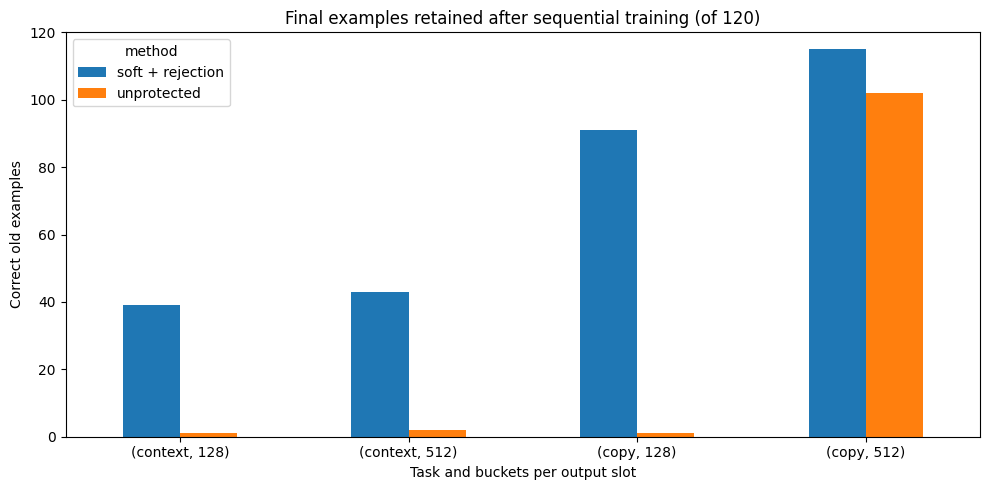

In [ ]:
# One chart; deliberately no fixed plot colors.
ax = results.pivot_table(index=['task', 'buckets_per_slot'],
                         columns='method', values='retained').plot.bar(
    figsize=(10, 5), rot=0, title='Final examples retained after sequential training (of 120)')
ax.set_ylabel('Correct old examples')
ax.set_xlabel('Task and buckets per output slot')
ax.set_ylim(0, 120)
plt.tight_layout()
plt.show()

## 7 · Use a pretrained brain **without the old training examples**

If you already have a `brain.pkl` from your original notebook, you can import its existing **per-bucket output behavior** using `import_existing=True`. This does **not** reconstruct which specific examples were previously learned, so the initial hash resistance is a heuristic rather than an exact historical importance estimate. Recompilation preserves every pre-import bucket's emitted output, assuming it fits `max_piece_len`; it cannot guarantee old example retention when hash parameters later change.

```python
# Load only trusted pickle files; unpickling arbitrary files can execute code.
with open('brain.pkl', 'rb') as f:
    pretrained_brain = pickle.load(f)

max_existing_piece_len = max(len(pretrained_brain.walk(k))
                             for k in range(pretrained_brain.local_D * pretrained_brain.max_input_len))
settings = OnlineConfig(max_piece_len=max(1, max_existing_piece_len),
                        rejection_threshold=3.0)
# Need pretrained_brain.cap >= settings.max_piece_len + 1.
model = OnlineSoftResistanceTrainer(
    pretrained_brain, settings, import_existing=True,
    initial_hash_resistance=2.0,
    initial_bucket_resistance=3.0,
    initial_empty_bucket_resistance=0.0,
)
# model.learn('new input', 'new output')
```

If your original `cap` is too small for the largest existing output, increase `cap` before importing, or keep the existing brain unchanged. The online trainer doesn't import the previous batch trainer's `N` / occurrence matrices; those require the original examples.

## 8 · Train directly from a CSV in constant **example-buffer** memory

Set `CSV_PATH`, `INPUT_COL`, `OUTPUT_COL` and model dimensions for your own data. This workflow uses **two streaming passes**: one to discover character vocabularies and maximum input length, and one to learn examples sequentially. It does not store old rows in a Python list. It still stores model parameters, output assignments and resistance arrays; memory is **not constant overall** and runtime is not guaranteed constant per example.

**Large input lengths can make `local_D × max_input_len` extremely large.** For a programming-task CSV, plan the alphabet, maximum tokenized input length, and number of buckets before running. This implementation uses character input tokens and character output symbols, while the brain can also accept a user-defined input token alphabet. Very long outputs must satisfy `len(output) <= len(input_tokens) * max_piece_len`.

Uncomment and configure this cell to run on a real CSV file. The code itself is executable when `CSV_PATH` is set.

In [ ]:
from pathlib import Path
import csv

CSV_PATH = "/content/python_repair_examples(1).csv"  # e.g., 'my_programming_tasks.csv'
INPUT_COL = 'instruction'
OUTPUT_COL = 'fixed_code'

if CSV_PATH is not None:
    # Pass 1: scan vocabulary and max input length without retaining rows.
    in_chars, out_chars, max_len, count = set(), set(), 0, 0
    with open(CSV_PATH, newline='', encoding='utf-8') as f:
        for row in csv.DictReader(f):
            inp, ans = row[INPUT_COL], row[OUTPUT_COL]
            in_chars.update(inp)
            out_chars.update(ans)
            max_len = max(max_len, len(inp))  # character-level input tokens
            count += 1
    print('Dataset rows:', count, 'input chars:', len(in_chars),
          'output chars:', len(out_chars), 'max input length:', max_len)

    # IMPORTANT: size these values based on available memory and output lengths.
    local_D = 128
    max_piece_len = 4
    random.seed(42)
    np.random.seed(42)
    csv_brain = BallTrapBrain(
        alphabet=sorted(in_chars), output=sorted(out_chars),
        local_D=local_D, max_input_len=max_len, hash_radius=2,
        direction_range=local_D, cap=max_piece_len + 1, bounce=10,
    )
    csv_model = OnlineSoftResistanceTrainer(
        csv_brain, OnlineConfig(max_piece_len=max_piece_len,
                                rejection_threshold=3.0, seed=42)
    )
    # Pass 2: learn a single row, then forget it. Checkpoint every 500 updates.
    with open(CSV_PATH, newline='', encoding='utf-8') as f:
        for step, row in enumerate(csv.DictReader(f), start=1):
            result = csv_model.learn(row[INPUT_COL], row[OUTPUT_COL])
            if step % 2 == 0:
                print('Rows processed:', step, csv_model.summary())
                csv_model.save_checkpoint('online_brain_state.pkl')
    csv_model.save_checkpoint('online_brain_state.pkl')
    print('Done:', csv_model.summary())
else:
    print('Set CSV_PATH to enable streaming CSV training.')

Dataset rows: 5000 input chars: 39 output chars: 46 max input length: 112
Rows processed: 2 {'seen': 2, 'accepted': 1, 'rejected': 1, 'already_correct': 0, 'persistent_buckets': 44, 'physical_deflectors': 14340, 'hash_edits': 0, 'bucket_overwrites': 0}
Rows processed: 4 {'seen': 4, 'accepted': 1, 'rejected': 3, 'already_correct': 0, 'persistent_buckets': 44, 'physical_deflectors': 14340, 'hash_edits': 0, 'bucket_overwrites': 0}


KeyboardInterrupt: 

## 9 · Limitations and how to improve it

1. **No absolute retention guarantee.** Resistance is local and soft. Updates still can redirect old inputs to other buckets. A threshold blocks updates with high *estimated* disturbance, not actual forgetting (the latter cannot be measured without old information).
2. **Initial importance is approximate.** Incrementing resistance after every successful example records use, not causal contribution. Stronger methods could track how often parameter perturbations actually affect a learned output, but accurate guarantees typically need stored constraints or replay.
3. **Tradeoff:** raising resistance or lowering rejection threshold will usually protect earlier associations at the cost of accepting fewer new examples.
4. **Output capacity:** targets require at most `len(input tokens) × max_piece_len` output characters. Physical chains add deflectors as needed; `max_piece_len` is bounded by `cap - 1`.
5. **Online search is heuristic.** Greedy coordinate sweeps can miss better joint hash changes. They train on only one example, unlike the original full-dataset/GPU search.
6. **Imported brains:** snapshotting existing outputs is useful but does not recover which past examples visited which hash features. It may increase physical deflector count.
7. **Checkpoint safety:** the `.pkl` examples use Python pickle for convenience. Load only your own trusted checkpoints.

You can adjust weights and the threshold in `OnlineConfig` without changing the core brain architecture.